# Лабораторная работа № 1.1
---
«Очистка и преобразование данных.
Определение «выбросов» (outliers) в датасете»

Рязанцев Георгий Борисович

In [ ]:
import pandas as pd
#from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv('Customers.csv', sep=";", decimal=",") 

In [4]:
print(df) 
print(df.shape)
print(df.dtypes) 

          Number  Customer_id   Prices        Date
0        1234491     337544.0   539.00  01.01.2018
1        1234494     171642.0   153.30  01.01.2018
2        1234497     260596.0    55.30  01.01.2018
3        1234498    1105609.0   752.50  01.01.2018
4        1234500     982696.0  4410.00  01.01.2018
...          ...          ...      ...         ...
1048570  4128741     745815.0   489.30  13.03.2019
1048571  4128746    3343412.0   734.30  13.03.2019
1048572  4128752     451277.0  1757.00  13.03.2019
1048573  4128755     135078.0  4650.10  13.03.2019
1048574  4128758     512652.0  9261.00  13.03.2019

[1048575 rows x 4 columns]
(1048575, 4)
Number           int64
Customer_id    float64
Prices          object
Date            object
dtype: object


In [5]:
df_numeric = []
df_numeric_not = []

def define_numeric(data=df):
    global df_numeric
    global df_numeric_not
    df_numeric = data.select_dtypes(include=[np.number]).columns.values 
    df_numeric_not = data.select_dtypes(exclude=[np.number]).columns.values

In [6]:
define_numeric()

print(df_numeric)
print(df_numeric_not)

['Number' 'Customer_id']
['Prices' 'Date']


In [7]:
df[['Prices', 'Number', 'Customer_id']] = df[['Prices', 'Number', 'Customer_id']].astype(float) 

In [8]:
define_numeric()

print(df_numeric)
print(df_numeric_not)

['Number' 'Customer_id' 'Prices']
['Date']


In [9]:
print(df.describe()) 

             Number   Customer_id        Prices
count  1.048575e+06  1.048566e+06  1.048575e+06
mean   2.570549e+06  1.485835e+06  2.136475e+03
std    8.434932e+05  8.833536e+05  3.243518e+03
min    1.234491e+06  0.000000e+00 -3.430000e+01
25%    1.804274e+06  7.050775e+05  7.049000e+02
50%    2.524455e+06  1.438339e+06  1.358000e+03
75%    3.291542e+06  2.124041e+06  2.422000e+03
max    4.128758e+06  3.343412e+06  8.190966e+05


<Axes: >

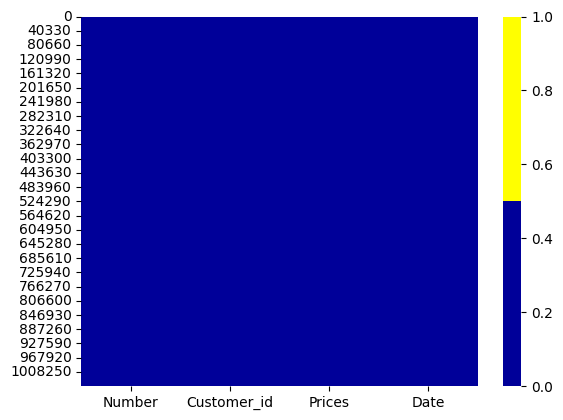

In [10]:
cols = df.columns[:4]
colours = ['#000099', '#ffff00']
sns.heatmap(df[cols].isnull(), cmap=sns.color_palette(colours))

In [11]:
def missin():
    for col in df.columns:
        pct_missing = np.count_nonzero(df[col].isnull())
        print('{} - {}'.format(col, pct_missing))

In [12]:
missin()

Number - 0
Customer_id - 9
Prices - 0
Date - 0


In [13]:
median = df['Customer_id'].median()
print(median)
df['Customer_id'] = df['Customer_id'].fillna(median)

1438339.0


In [14]:
missin()

Number - 0
Customer_id - 0
Prices - 0
Date - 0


In [15]:
#---my---#
df["DateTime"] = pd.to_datetime(df["Date"], format="%d.%m.%Y", errors="coerce") 

2136.4745250935794
      Number  Customer_id  Prices        Date   DateTime
0  1234491.0     337544.0   539.0  01.01.2018 2018-01-01
1  1234494.0     171642.0   153.3  01.01.2018 2018-01-01
2  1234497.0     260596.0    55.3  01.01.2018 2018-01-01
3  1234498.0    1105609.0   752.5  01.01.2018 2018-01-01
4  1234500.0     982696.0  4410.0  01.01.2018 2018-01-01


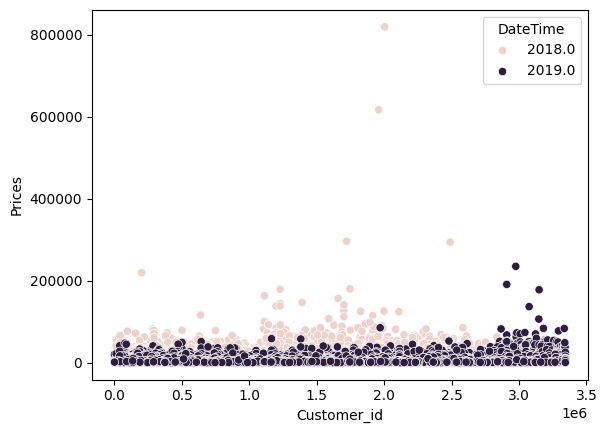

In [16]:
sns.scatterplot(x = df['Customer_id'], y = df['Prices'], hue = df["DateTime"].dt.year)
print(df.Prices.mean())
print(df.head()) 

Самостоятельная работа

In [28]:
df_clean = df.drop(columns=["Date"]).copy()
df_clean = df_clean.dropna()
df_clean = df_clean[df_clean["Prices"] <= 100_000]

<Axes: xlabel='Customer_id', ylabel='Prices'>

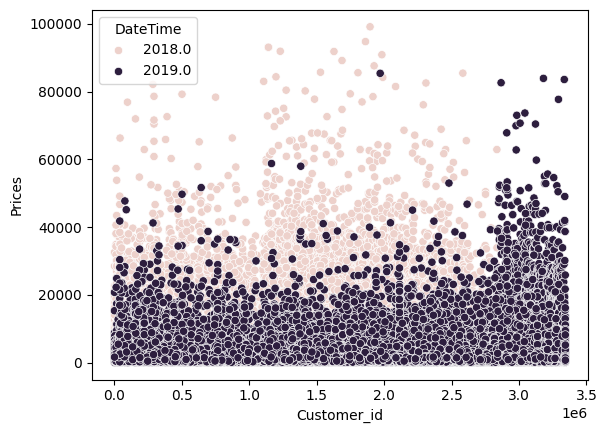

In [ ]:
sns.scatterplot(x = df_clean['Customer_id'], y = df_clean['Prices'], hue = df_clean["DateTime"].dt.year)

In [27]:
print(df_clean[df_clean["Prices"]>10_000_000])

Empty DataFrame
Columns: [Number, Customer_id, Prices, DateTime]
Index: []


In [ ]:
df_100 = df_clean[df_clean["Prices"]<=100].copy()
#print(df_100)

In [30]:
df_12 = df_clean.copy()
df_12["Prices"] = df_12["Prices"].apply(lambda x:x*1.2)
print(max(df_clean["Prices"]))
print(max(df_12["Prices"]))


99102.5
118923.0


### Вопросы для самоконтроля
---
1. Какая библиотека Python применяется для работы с данными в части
их загрузки в среду и удаления резко отличающихся значений?

— Pandas

2. Как называется совокупность показателей, позволяющих исследуемую
совокупность?

— Статистические показатели

3. Назовите основные подходы к выявлению пропущенных значений в
совокупности.

— Удаление, замена, восстановление

4. Для чего применяется диаграмма рассеяния на этапе подготовки и
очистки данных?

— Для выявления выбросов и взаимосвязей между данными.

5. Библиотека Python для построения диаграммы рассеяния. 

— Matplotlib, Seaborn